# Разбор упражнений к лекции 8

Условия — раздел 9 конспекта [`lecture08.md`](lecture08.md); краткие ответы без кода — [`exercises08.md`](exercises08.md). На семинаре — 8.0 и 8.3, остальные домашние. **Сначала попробуйте сами**, потом сверяйтесь. Каждый разбор: условие → решение по пунктам → проверка кодом и картинка там, где она помогает. Нужен CasADi: `uv run --group casadi jupyter lab`; в Colab первая ячейка ставит его сама.

In [1]:
%matplotlib inline

import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space
from scipy.optimize import fsolve
from l8helpers import *  # окружность, клюв, цепь на стержнях, портфель (собираются из build_demo08.py)

## 8.0. Разминка — счёт руками

**Условие.** *Суть: система $\nabla_xL=0$, $g=0$ на задачах с известным ответом.*

- (а) Ближайшая к $x_0$ точка плоскости $q^\top x=d$. Выпишите $L$ и решите систему. Сравните ответ с проекцией из лекции 2.
- (б) $\min\ x_1+x_2$ при $x_1^2+x_2^2=1$. Найдите оба решения системы и их $\lambda$. Какое из них минимум?
- (в) Ящик наибольшего объёма при площади поверхности $6$ (Л3, упражнение 13.10). Найдите $\lambda$ в решении $x=y=z=1$ и объясните его знак.

**Решение.**

**(а) Ближайшая точка плоскости.** Функция Лагранжа:

$$
L=\tfrac12\lVert x-x_0\rVert^2-\lambda\,(q^\top x-d) .
$$

Из $\nabla_xL=x-x_0-\lambda q=0$ получаем $x=x_0+\lambda q$. Подставим в $q^\top x=d$: $q^\top x_0+\lambda\lVert q\rVert^2=d$. Отсюда

$$
\lambda=\frac{d-q^\top x_0}{\lVert q\rVert^2},\qquad x^\ast=x_0+\frac{d-q^\top x_0}{\lVert q\rVert^2}\,q .
$$

Это формула проекции на плоскость из лекции 2. Множитель — расстояние до плоскости со знаком, в единицах $\lVert q\rVert$. Второй порядок: $\nabla^2_{xx}L=I\succ0$, минимум.

**(б) $\min x_1+x_2$ на окружности.** $g=x_1^2+x_2^2-1$, $\nabla f=(1,1)=\lambda(2x_1,2x_2)$, значит $x_1=x_2=1/(2\lambda)$; из $g=0$: $2/(4\lambda^2)=1$, $\lambda=\pm1/\sqrt2$. Два решения: $x=(1,1)/\sqrt2$ с $\lambda=1/\sqrt2$ и $x=-(1,1)/\sqrt2$ с $\lambda=-1/\sqrt2$. Минимум — второе, $f=-\sqrt2$: там $\nabla^2_{xx}L=\nabla^2f-\lambda\nabla^2g=0+\tfrac{1}{\sqrt2}\cdot2I=\sqrt2\,I\succ0$; в первом $-\sqrt2\,I$ — максимум.

**(в) Ящик.** Максимизируем $V=xyz$ при $S=2(xy+yz+zx)=6$. Условие $\nabla V=\lambda\nabla S$: $(yz,\,xz,\,xy)=2\lambda(y+z,\,x+z,\,x+y)$; при $x=y=z=1$ это $(1,1,1)=\lambda(4,4,4)$, $\lambda=1/4$. Знак положительный — потому что задача на максимум и ограничение «помогает»: $\lambda=\partial V^\ast/\partial S$, лишняя единица площади даёт $1/4$ объёма (проверка: $V^\ast(S)=(S/6)^{3/2}$, производная в $S=6$ равна $\tfrac32\cdot\tfrac16=\tfrac14$). В записи «минимизируем $-V$» множитель $-1/4$.

## 8.1. Две точки на окружности

**Условие.** (с кодом). *Суть: редуцированный гессиан различает минимум и максимум.*

- (а) Решите систему из §2.1 функцией `fsolve` из двух стартов. Получите обе точки и оба $\lambda$.
- (б) Для каждой точки постройте $Z$ (`null_space`) и редуцированный гессиан. Повторите для $a=(0.3,\ 0.1)$. Что изменилось?

**Решение.**

**(а)** Система $(x-a)-\lambda x=0$, $\tfrac12(\lVert x\rVert^2-1)=0$ из двух стартов даёт $x=\pm a/\sqrt5$ с $\lambda=1\mp\sqrt5$.

**(б)** $J=\nabla g^\top=x^\top$, базис $\ker J$ — вектор $Z=(-x_2,x_1)^\top$; $\nabla^2_{xx}L=\nabla^2f-\lambda\nabla^2g=(1-\lambda)I$, редуцированный гессиан $Z^\top(1-\lambda)IZ=1-\lambda$: $+\sqrt5$ в ближней точке (минимум), $-\sqrt5$ в дальней (максимум). Для $a=(0.3,0.1)$ — точки внутри круга — те же две точки $\pm a/\lVert a\rVert$, но $\lambda=1\mp0.316$: в минимуме теперь $\lambda=0.684>0$. **Знак множителя сменился, а ответ нет**: минимум отличает редуцированный гессиан $1-\lambda=\pm0.316$, не знак $\lambda$.

In [2]:
def circle_system(z, a):
    """Три уравнения задачи 1 для точки a: две компоненты grad f = lambda grad g и ограничение."""
    x1, x2, lam = z                                                   # неизвестные: точка и множитель
    return [x1 - a[0] - lam * x1,                                     # первая компонента
            x2 - a[1] - lam * x2,                                     # вторая компонента
            x1**2 + x2**2 - 1]                                        # точка на окружности


def classify(a):
    """Оба решения системы и редуцированный гессиан в каждом."""
    rows = []
    for z0 in ([1, 0.5, 0], [-1, -0.5, 0]):
        z = fsolve(lambda z: circle_system(z, a), z0, xtol=1e-14)      # (x, lam) из старта z0
        x, lam = z[:2], z[2]
        Z = null_space(x.reshape(1, -1))                               # базис ker J, J = grad g^T = x^T
        H = (1 - lam) * np.eye(2)                                      # hess_xx L = hess f - lam hess g = (1 - lam) I
        red = (Z.T @ H @ Z).item()                                     # редуцированный гессиан — число
        rows.append((x, lam, red, "минимум" if red > 0 else "максимум"))
    return rows

for a in (np.array([2.0, 1.0]), np.array([0.3, 0.1])):
    print(f"a = {a}:")
    for x, lam, red, kind in classify(a):
        print(f"   x = ({x[0]:+.4f}, {x[1]:+.4f}), lambda = {lam:+.4f}, Z^T H Z = {red:+.4f} -> {kind}")

a = [2. 1.]:
   x = (+0.8944, +0.4472), lambda = -1.2361, Z^T H Z = +2.2361 -> минимум
   x = (-0.8944, -0.4472), lambda = +3.2361, Z^T H Z = -2.2361 -> максимум
a = [0.3 0.1]:
   x = (+0.9487, +0.3162), lambda = +0.6838, Z^T H Z = +0.3162 -> минимум
   x = (-0.9487, -0.3162), lambda = +1.3162, Z^T H Z = -0.3162 -> максимум


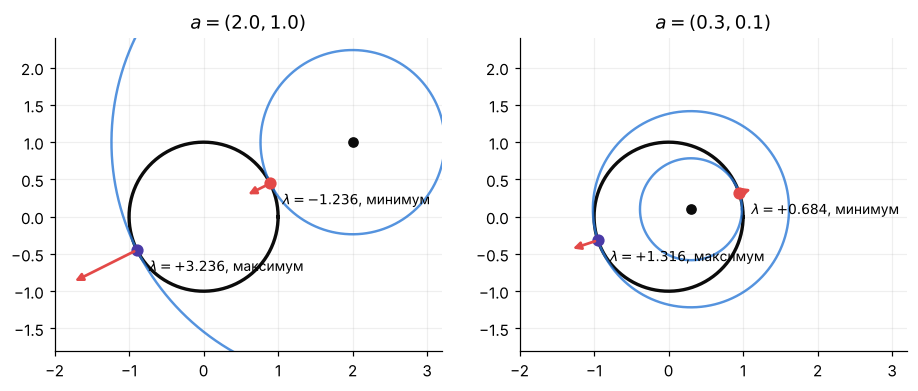

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, a in zip(axes, (np.array([2.0, 1.0]), np.array([0.3, 0.1]))):
    unit_circle(ax)
    rows = classify(a)
    level_circles(ax, a, [0.5 * np.sum((x - a) ** 2) for x, *_ in rows], color=BLUE, lw=1.6)
    for x, lam, red, kind in rows:
        ax.plot(*x, "o", color=RED if red > 0 else VIOLET, ms=7)
        ax.annotate(f"$\\lambda={lam:+.3f}$, {kind}", x, (8, -14), textcoords="offset points", fontsize=9)
        ax.annotate("", x + 0.3 * (x - a), x, arrowprops=dict(arrowstyle="-|>", color=RED, lw=1.8))   # grad f
    ax.plot(*a, "o", color=INK); ax.set_aspect("equal"); ax.set_xlim(-2, 3.2); ax.set_ylim(-1.8, 2.4)
    ax.set_title(f"$a=({a[0]}, {a[1]})$")
plt.show()

## 8.2. Клюв

**Условие.** (с кодом). *Суть: у острия нужное $\hat\lambda$ уходит в бесконечность.*

Возьмите точки кривой $x_2=x_1^{2/3}$ при $x_1=10^{-1},\dots,10^{-6}$. Посчитайте $\lVert\nabla g\rVert$, $\hat\lambda=\nabla f^\top\nabla g/\lVert\nabla g\rVert^2$ и невязку $\lVert\nabla f-\hat\lambda\nabla g\rVert$. Покажите, что $\hat\lambda$ растёт как $x_1^{-2/3}$, а невязка стремится к $1$. Что будет с LICQ, если записать ту же кривую как $x_2-x_1^{2/3}=0$?

**Решение.**

Вдоль кривой $x_2=x_1^{2/3}$: $\nabla g=(-2x_1,\,3x_1^{4/3})$, $\lVert\nabla g\rVert\approx2x_1$ при малых $x_1$; оценка $\hat\lambda=\nabla f^\top\nabla g/\lVert\nabla g\rVert^2=3x_1^{4/3}/(4x_1^2+9x_1^{8/3})\approx\tfrac34x_1^{-2/3}\to\infty$, а невязка $\lVert\nabla f-\hat\lambda\nabla g\rVert\to1$: $\nabla g$ ложится горизонтально, и вертикальный $\nabla f=(0,1)$ им не уравновесить. С ограничением $g=x_2-x_1^{2/3}$ кривая та же, но $g$ **не дифференцируема** в нуле ($\partial g/\partial x_1=-\tfrac23x_1^{-1/3}\to\infty$): теорема раздела 3 требует непрерывной дифференцируемости и к этой записи неприменима тоже. LICQ — условие на *запись* ограничений, а не только на множество.

      x1   |grad g|    lambda^  0.75 x1^(-2/3)   невязка
   1e-06   2.00e-06    7498.31         7500.00   0.99989
   1e-05   2.00e-05    1614.14         1615.83   0.99948
   1e-04   2.00e-04     346.44          348.12   0.99759
   1e-03   2.02e-03      73.35           75.00   0.98894
   1e-02   2.10e-02      14.63           16.16   0.95155
   1e-01   2.44e-01       2.34            3.48   0.82068


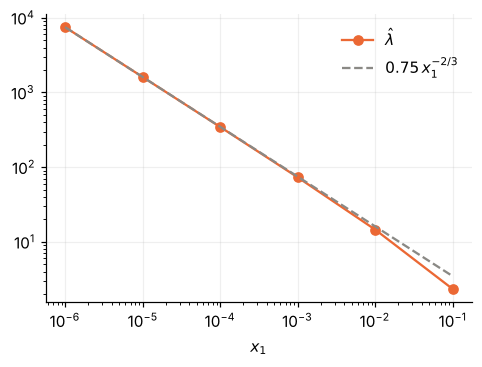

In [4]:
xs = np.logspace(-6, -1, 6)
print(f"{'x1':>8s} {'|grad g|':>10s} {'lambda^':>10s} {'0.75 x1^(-2/3)':>15s} {'невязка':>9s}")
for x1 in xs:
    gg, lam_hat, _ = cusp_grad(x1)                                      # из l8helpers: grad g, оценка lambda, угол
    res = np.linalg.norm(np.array([0.0, 1.0]) - lam_hat * gg)
    print(f"{x1:8.0e} {np.linalg.norm(gg):10.2e} {lam_hat:10.2f} {0.75 * x1 ** (-2 / 3):15.2f} {res:9.5f}")
fig, ax = plt.subplots(figsize=(5, 3.4))
lams = [cusp_grad(x)[1] for x in xs]
ax.loglog(xs, lams, "o-", color=ORANGE, label=r"$\hat\lambda$"); ax.loglog(xs, 0.75 * xs ** (-2 / 3), "--", color=GRAY, label="$0.75\\,x_1^{-2/3}$")
ax.set_xlabel("$x_1$"); ax.legend(); plt.show()

## 8.3. Кривизна ограничения

**Условие.** *Суть: решает $\nabla^2_{xx}L$ вдоль $T$, а не $\nabla^2f$.*

- (а) $f=x_2$ на параболе $x_2=cx_1^2$. При каких $c$ ноль — минимум, максимум, ни то ни другое?
- (б) $f=x_1^2-x_2^2$ на прямой $x_2=0$. Покажите, что ноль — строгий минимум, хотя $\nabla^2f$ индефинитен (собственные числа разных знаков).

**Решение.**

**(а)** Точка параболы $x(t)=(t,\ ct^2)$, тогда $f(x(t))=ct^2$ и вторая производная равна $2c$. То же даёт $Z^\top\nabla^2_{xx}L\,Z$ с $Z=(1,0)^\top$ и $\nabla^2_{xx}L=\operatorname{diag}(2c,0)$.

- $c>0$ — строгий минимум, $c<0$ — строгий максимум.
- $c=0$: ограничение — прямая $x_2=0$, на ней $f\equiv0$. Каждая точка — нестрогий минимум и нестрогий максимум сразу. Необходимое условие $2c\ge0$ выполнено, достаточное $2c>0$ — нет. Теорема молчит.

**(б)** $f=x_1^2-x_2^2$, $g=x_2$: $\nabla f(0,0)=0$, значит $\lambda=0$ и $\nabla^2_{xx}L=\nabla^2f=\operatorname{diag}(2,-2)$ — индефинитна. Но $J=(0,1)$, $Z=(1,0)^\top$, редуцированный гессиан $Z^\top\operatorname{diag}(2,-2)Z=2>0$: строгий минимум. На прямой $x_2=0$ функция равна $x_1^2$, отрицательное направление кривизны $(0,1)$ запрещено ограничением.

## 8.4. Цепь на стержнях: силы и цена длины

**Условие.** (с кодом). *Суть: условие первого порядка — баланс сил, а множитель — производная оптимума.*

- (а) Решите задачу 2 из введения в CasADi. Проверьте: горизонтальная составляющая $2\lambda_j\Delta y_j$ одинакова во всех стержнях, а вертикальные составляющие на опорах дают вес цепи.
- (б) Удлините стержни на $1\,\%$ и на $5\,\%$. Сравните изменение $f^\ast$ с предсказанием $\sum_j\lambda_j\,\Delta(\ell^2)$. Почему при $5\,\%$ расхождение больше?

**Решение.**

**(а)** Условие $\nabla_xL=0$ для груза $i$ — баланс сил: $2\lambda_{i-1}\Delta y_{i-1}=2\lambda_i\Delta y_i$ (горизонтальная составляющая передаётся по цепи без изменений) и $2\lambda_{i-1}\Delta z_{i-1}-2\lambda_i\Delta z_i=w$. Суммируя вертикальные уравнения по трём грузам, получаем, что вертикальные составляющие на двух опорах в сумме равны весу цепи $3w=29.43$ Н — по $14.72$ Н на каждую.

**(б)** $\Delta f^\ast\approx\sum_j\lambda_j\,\Delta(\ell^2)$: при $+1\,\%$ предсказание $-3.239$ против пересчёта $-3.226$ (расхождение $0.013$), при $+5\,\%$ — $-6.702$ против $-6.408$ (расхождение $0.29$). Формула $\partial f^\ast/\partial b=\lambda^\ast$ — производная, то есть первый порядок; расхождение растёт как квадрат шага по $b$ — это вторая производная $f^\ast(b)$, которую множители не знают.

In [5]:
ch = rod_chain(); v, lam, st = solve_rod_chain(ch); chk = chain_checks(ch, v, lam)
y, z = chain_xy(ch, v); dy, dz = np.diff(y), np.diff(z)
Fh, Fv = 2 * lam * dy, 2 * lam * dz                                      # составляющие силы стержня j
print(f"горизонтальная 2 lam_j dy_j: разброс по стержням {np.ptp(Fh):.1e} Н при значении {Fh[0]:.3f} Н")
print(f"вертикальные на опорах: {abs(Fv[0]):.2f} + {abs(Fv[-1]):.2f} = {abs(Fv[0]) + abs(Fv[-1]):.2f} Н, вес цепи {ch['N'] * ch['w']:.2f} Н")
f0 = ch["w"] * z[1:-1].sum()
for k in (1.01, 1.05):
    ch2 = rod_chain(L_total=5.0 * k); v2, _, _ = solve_rod_chain(ch2, v0=v)
    f2 = ch2["w"] * chain_xy(ch2, v2)[1][1:-1].sum()
    pred = f0 + lam.sum() * (ch2["ell"] ** 2 - ch["ell"] ** 2)             # первый порядок по множителям
    print(f"+{(k - 1) * 100:.0f} %: f* = {f2:.3f}, по множителям {pred:.3f}, расхождение {f2 - pred:.3f}")

горизонтальная 2 lam_j dy_j: разброс по стержням 7.5e-13 Н при значении -13.061 Н
вертикальные на опорах: 14.72 + 14.72 = 29.43 Н, вес цепи 29.43 Н
+1 %: f* = -3.226, по множителям -3.239, расхождение 0.013
+5 %: f* = -6.408, по множителям -6.702, расхождение 0.294


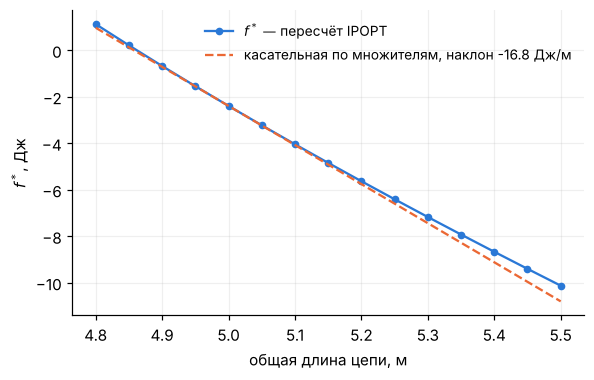

In [6]:
lengths = np.linspace(4.8, 5.5, 15); f_len = []                         # общая длина цепи, м
for total in lengths:
    chL = rod_chain(L_total=total); vL, _, _ = solve_rod_chain(chL, v0=v)
    f_len.append(chL["w"] * chain_xy(chL, vL)[1][1:-1].sum())
slope = lam.sum() * 2 * ch["ell"] / (ch["N"] + 1)                        # d f*/dL = sum lam_j d(ell^2)/dL
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(lengths, f_len, "o-", color=BLUE, ms=4, label="$f^*$ — пересчёт IPOPT")
ax.plot(lengths, f0 + slope * (lengths - 5), "--", color=ORANGE, label=f"касательная по множителям, наклон {slope:.1f} Дж/м")
ax.set_xlabel("общая длина цепи, м"); ax.set_ylabel("$f^*$, Дж"); ax.legend(fontsize=9); plt.show()

## 8.5. Цена доходности

**Условие.** (с кодом). *Суть: $df^\ast/d\rho=\lambda_\rho$.*

Решите систему для портфеля из §5.2 при $\rho$ от $6$ до $14\,\%$. Почему она линейная? Сравните численную производную $f^\ast(\rho)$ с $\lambda_\rho$. При какой $\rho$ доля первого актива становится отрицательной?

**Решение.**

Система ККТ: $\Sigma x-\lambda_1\mathbf1-\lambda_2r=0$, $\mathbf1^\top x=1$, $r^\top x=\rho$ — **линейная**, потому что $f$ квадратична (её градиент линеен) и ограничения линейны: одна матрица $6\times6$ и `np.linalg.solve`. $f^\ast(\rho)$ — парабола, её производная в $\rho=0.10$ совпадает с $\lambda_\rho=0.257$ до $10^{-10}$. Доля первого актива $x_1(\rho)$ линейна по $\rho$ и обращается в ноль при $\rho=10.64\,\%$; выше этого в задаче лекции 3 ограничение $x_1\ge0$ становится активным, появляется третий множитель, и цена доходности меняется: при $12\,\%$ она равна $0.47$ (Л3 §8), а здесь, с короткой позицией, была бы $0.35$.

max |df*/drho - lambda_rho| по сетке = 7.8e-15
x_1 = 0 при rho = 10.64 %;  lambda_rho при 10 % = 0.257, при 12 % = 0.351


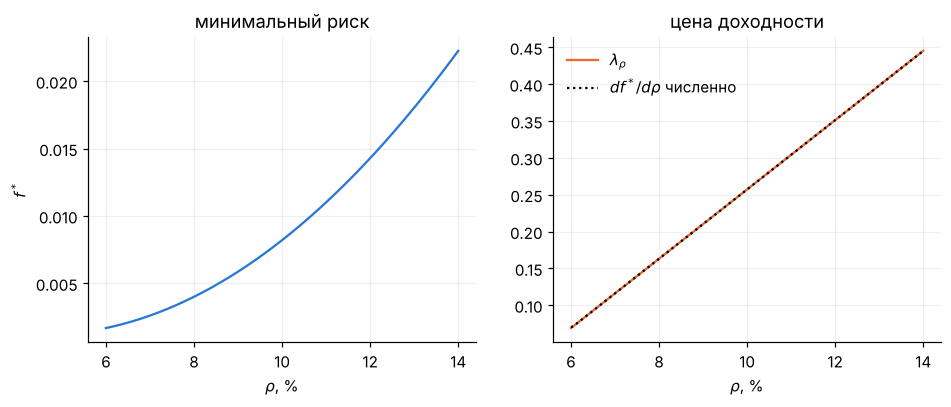

In [7]:
rhos = np.linspace(0.06, 0.14, 161)
fs = np.array([portfolio_eq(r)[1] for r in rhos])                       # f*(rho)
lams = np.array([portfolio_eq(r)[2][1] for r in rhos])                  # lambda_rho(rho)
dfs = np.gradient(fs, rhos)                                             # численная производная
print(f"max |df*/drho - lambda_rho| по сетке = {np.abs(dfs[2:-2] - lams[2:-2]).max():.1e}")
x1 = np.array([portfolio_eq(r)[0][0] for r in rhos])
print(f"x_1 = 0 при rho = {np.interp(0, x1[::-1], rhos[::-1]) * 100:.2f} %;  lambda_rho при 10 % = {portfolio_eq(0.10)[2][1]:.3f}, при 12 % = {portfolio_eq(0.12)[2][1]:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(100 * rhos, fs, color=BLUE); axes[0].set_xlabel("$\\rho$, %"); axes[0].set_ylabel("$f^*$"); axes[0].set_title("минимальный риск")
axes[1].plot(100 * rhos, lams, color=ORANGE, label="$\\lambda_\\rho$"); axes[1].plot(100 * rhos, dfs, "k:", label="$df^*/d\\rho$ численно")
axes[1].set_xlabel("$\\rho$, %"); axes[1].legend(); axes[1].set_title("цена доходности"); plt.show()

## 8.6. Для желающих: доказательства

**Условие.** *Суть: теорема о неявной функции превращает задачу с равенствами в задачу без них.*

Докажите теоремы §3.2 и §4.2 полностью. Докажите формулу цены из §5.2 и найдите условие, при котором $x^\ast(b)$ и $\lambda^\ast(b)$ дифференцируемы.

**Решение.**

**Теорема первого порядка (§3.2).** Пусть $x^\ast$ — локальный минимум $f$ при $g(x)=0$, $g:\mathbb R^n\to\mathbb R^m$ непрерывно дифференцируема, $\operatorname{rank}J(x^\ast)=m$. Переставим координаты так, что $x=(u,s)$, $u\in\mathbb R^{n-m}$, $s\in\mathbb R^m$, и квадратный блок $\partial g/\partial s$ невырожден в $x^\ast$ (это и есть LICQ: среди $n$ столбцов $J$ есть $m$ независимых). По теореме о неявной функции около $x^\ast$ уравнение $g(u,s)=0$ однозначно разрешимо: $s=\sigma(u)$, $\sigma$ непрерывно дифференцируема, $\sigma(u^\ast)=s^\ast$. Положим $\psi(u)=(u,\sigma(u))$ — параметризация поверхности. Дифференцируя $g(\psi(u))\equiv0$, получаем $J\,\psi'(u)=0$: столбцы $\psi'(u^\ast)$ ($n-m$ штук, независимые — в верхней части стоит единичная матрица) лежат в $\ker J$, а размерность $\ker J$ равна $n-m$, так что это базис, $Z=\psi'(u^\ast)$.

Функция $\tilde f(u)=f(\psi(u))$ имеет в $u^\ast$ локальный минимум без ограничений, поэтому $\nabla\tilde f(u^\ast)=Z^\top\nabla f(x^\ast)=0$: вектор $\nabla f(x^\ast)$ ортогонален $\ker J$. Ортогональное дополнение ядра — пространство строк: $\nabla f(x^\ast)=J^\top\lambda$ для некоторого $\lambda$, и он единственный, так как строки $J$ независимы.

**Теорема второго порядка (§4.2).** В той же параметризации $\nabla^2\tilde f(u^\ast)=Z^\top\nabla^2f\,Z+\sum_k\partial_kf\,\nabla^2\psi_k$. Второй член содержит кривизну параметризации; избавимся от него, продифференцировав дважды $g_j(\psi(u))\equiv0$: $Z^\top\nabla^2g_j\,Z+\sum_k\partial_kg_j\,\nabla^2\psi_k=0$. Умножим на $\lambda_j$, сложим и используем $\nabla f=\sum_j\lambda_j\nabla g_j$:

$$
\nabla^2\tilde f(u^\ast)=Z^\top\Big(\nabla^2f-\sum_j\lambda_j\nabla^2g_j\Big)Z=Z^\top\nabla^2_{xx}L\,Z .
$$

Для задачи без ограничений (лекция 4): $\nabla^2\tilde f(u^\ast)\succeq0$ необходимо, $\succ0$ достаточно для строгого минимума; $u^\ast$ — строгий минимум $\tilde f$ тогда и только тогда, когда $x^\ast$ — строгий минимум $f$ на поверхности, потому что $\psi$ — взаимно однозначное гладкое соответствие между окрестностью $u^\ast$ и куском поверхности.

**Формула чувствительности (§5.2).** Семейство задач $g(x)=b$. Система $F(x,\lambda,b)=(\nabla f(x)-J(x)^\top\lambda,\ g(x)-b)=0$ имеет в $(x^\ast,\lambda^\ast,b_0)$ матрицу Якоби по $(x,\lambda)$

$$
K=\begin{pmatrix}\nabla^2_{xx}L&-J^\top\\ J&0\end{pmatrix}.
$$

Она невырождена, если выполнено LICQ и **достаточное** условие второго порядка $Z^\top\nabla^2_{xx}LZ\succ0$ (упражнение: пусть $K(p,q)=0$; из $Jp=0$ следует $p=Zw$, умножаем первое уравнение на $p^\top$ и получаем $w^\top Z^\top\nabla^2_{xx}LZ\,w=0$, откуда $w=0$, $p=0$, затем $J^\top q=0$ и $q=0$ по LICQ). Тогда по теореме о неявной функции $x^\ast(b)$ и $\lambda^\ast(b)$ непрерывно дифференцируемы около $b_0$ — это и есть условие, которого не хватало. Дальше две строки конспекта: $f^\ast(b)=L(x^\ast(b),\lambda^\ast(b),b)$, производная по $b$ сводится к $\partial L/\partial b=\lambda^\ast(b)$. Та же матрица $K$ — матрица системы Ньютона–Лагранжа лекции 9.